In [1]:
import re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, classification_report)
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
RANDOM_STATE = 42

In [2]:
# --- Upload the CSV in Colab (skip this cell if the file is already present) ---
try:
    from google.colab import files
    uploaded = files.upload()
    CSV_PATH = list(uploaded.keys())[0]
except Exception:
    CSV_PATH = 'train_v2_drcat_02.csv'   # DAIGT V2 file; change if your file name differs

df = pd.read_csv(CSV_PATH)
print(df.shape)
print(df.columns.tolist())
df.head()

(44868, 5)
['text', 'label', 'prompt_name', 'source', 'RDizzl3_seven']


,text,label,prompt_name,source,RDizzl3_seven
0,Phones\n\nModern humans today are always on th...,0,Phones and driving,persuade_corpus,False
1,This essay will explain if drivers should or s...,0,Phones and driving,persuade_corpus,False
2,Driving while the use of cellular devices\n\nT...,0,Phones and driving,persuade_corpus,False
3,Phones & Driving\n\nDrivers should not be able...,0,Phones and driving,persuade_corpus,False
4,Cell Phone Operation While Driving\n\nThe abil...,0,Phones and driving,persuade_corpus,False


In [3]:
# --- Configure column names (edit these to match YOUR csv) ---
TEXT_COL  = 'text'
LABEL_COL = 'label'       # DAIGT V2: 0 = human, 1 = AI
MAX_PER_CLASS = 10000      # keeps training fast on a laptop / free Colab

df = df[[TEXT_COL, LABEL_COL]].dropna().rename(columns={TEXT_COL:'text', LABEL_COL:'label'})
df['label'] = df['label'].astype(int)
df = df.drop_duplicates(subset='text')

# Balance the classes by downsampling the larger one
n = min(df['label'].value_counts().min(), MAX_PER_CLASS)
df = pd.concat([df[df['label'] == k].sample(n=n, random_state=RANDOM_STATE) for k in sorted(df['label'].unique())])
df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
print('Final dataset:', df.shape)
print(df['label'].value_counts())

Final dataset: (20000, 2)
label
1    10000
0    10000
Name: count, dtype: int64


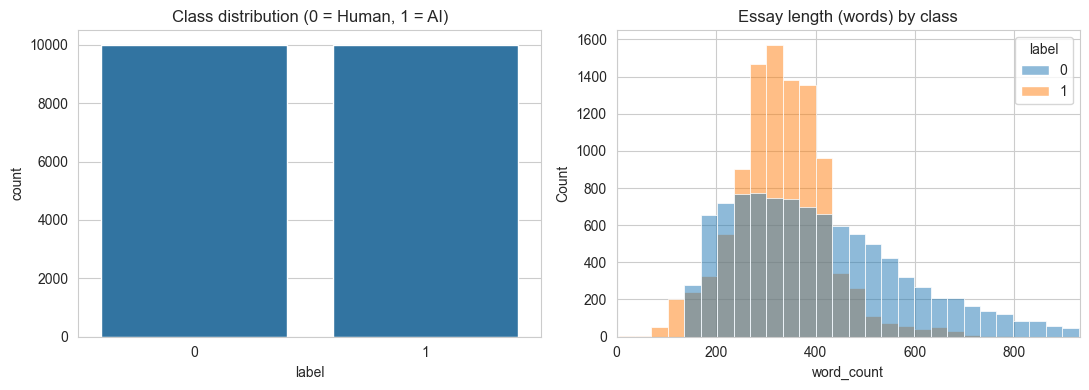

         count      mean         std    min    25%    50%    75%     max
label                                                                   
0      10000.0  417.7480  189.526746  144.0  272.0  382.0  520.0  1656.0
1      10000.0  329.9547   94.770579    4.0  274.0  328.0  386.0   785.0


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x='label', ax=ax[0])
ax[0].set_title('Class distribution (0 = Human, 1 = AI)')
df['word_count'] = df['text'].str.split().str.len()
sns.histplot(data=df, x='word_count', hue='label', bins=50, ax=ax[1], clip_on=True)
ax[1].set_xlim(0, df['word_count'].quantile(0.99))
ax[1].set_title('Essay length (words) by class')
plt.tight_layout(); plt.savefig('eda.png', dpi=150); plt.show()
print(df.groupby('label')['word_count'].describe())

In [5]:
def clean_text(t):
    t = str(t).lower()
    t = re.sub(r'http\S+|www\S+', ' ', t)
    t = re.sub(r'[^a-z\s]', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

df['clean'] = df['text'].apply(clean_text)
df[['text','clean']].head(3)

,text,clean
0,It is well-documented that eating a wide varie...,it is well documented that eating a wide varie...
1,"Dear Principle,\n\nSome of my friends do commu...",dear principle some of my friends do community...
2,"In the article ""Driveless Cars Are Coming"", Th...",in the article driveless cars are coming the a...


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df['clean'], df['label'], test_size=0.2, stratify=df['label'], random_state=RANDOM_STATE)
print('Train:', len(X_train), ' Test:', len(X_test))
print('Train class counts:', y_train.value_counts().to_dict())
print('Test  class counts:', y_test.value_counts().to_dict())

Train: 16000  Test: 4000
Train class counts: {1: 8000, 0: 8000}
Test  class counts: {1: 2000, 0: 2000}


In [7]:
tfidf = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), max_features=50000, sublinear_tf=True)
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)
print('TF-IDF matrix:', Xtr.shape)

TF-IDF matrix: (16000, 50000)


In [8]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, C=1.0, random_state=RANDOM_STATE),
    'Naive Bayes':         MultinomialNB(alpha=0.1),
    'Linear SVM':          CalibratedClassifierCV(LinearSVC(C=1.0, random_state=RANDOM_STATE), cv=3),
}
rows, probs, preds = [], {}, {}
for name, m in models.items():
    m.fit(Xtr, y_train)
    p = m.predict_proba(Xte)[:, 1]
    yhat = (p >= 0.5).astype(int)
    probs[name], preds[name] = p, yhat
    rows.append({'Model': name,
                 'Accuracy':  accuracy_score(y_test, yhat),
                 'Precision': precision_score(y_test, yhat),
                 'Recall':    recall_score(y_test, yhat),
                 'F1-score':  f1_score(y_test, yhat),
                 'ROC-AUC':   roc_auc_score(y_test, p)})
results = pd.DataFrame(rows).set_index('Model').round(4)
results

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.9875,0.9985,0.9765,0.9874,0.9988
Naive Bayes,0.9762,0.9862,0.9660,0.9760,0.9978
Linear SVM,0.9932,0.9970,0.9895,0.9932,0.9997


In [9]:
# Detailed report for each model
for name in models:
    print('=' * 60); print(name)
    print(classification_report(y_test, preds[name], target_names=['Human', 'AI'], digits=4))

Logistic Regression
              precision    recall  f1-score   support

       Human     0.9770    0.9985    0.9876      2000
          AI     0.9985    0.9765    0.9874      2000

    accuracy                         0.9875      4000
   macro avg     0.9877    0.9875    0.9875      4000
weighted avg     0.9877    0.9875    0.9875      4000

Naive Bayes
              precision    recall  f1-score   support

       Human     0.9667    0.9865    0.9765      2000
          AI     0.9862    0.9660    0.9760      2000

    accuracy                         0.9762      4000
   macro avg     0.9765    0.9763    0.9762      4000
weighted avg     0.9765    0.9762    0.9762      4000

Linear SVM
              precision    recall  f1-score   support

       Human     0.9896    0.9970    0.9933      2000
          AI     0.9970    0.9895    0.9932      2000

    accuracy                         0.9932      4000
   macro avg     0.9933    0.9932    0.9932      4000
weighted avg     0.9933    0.99

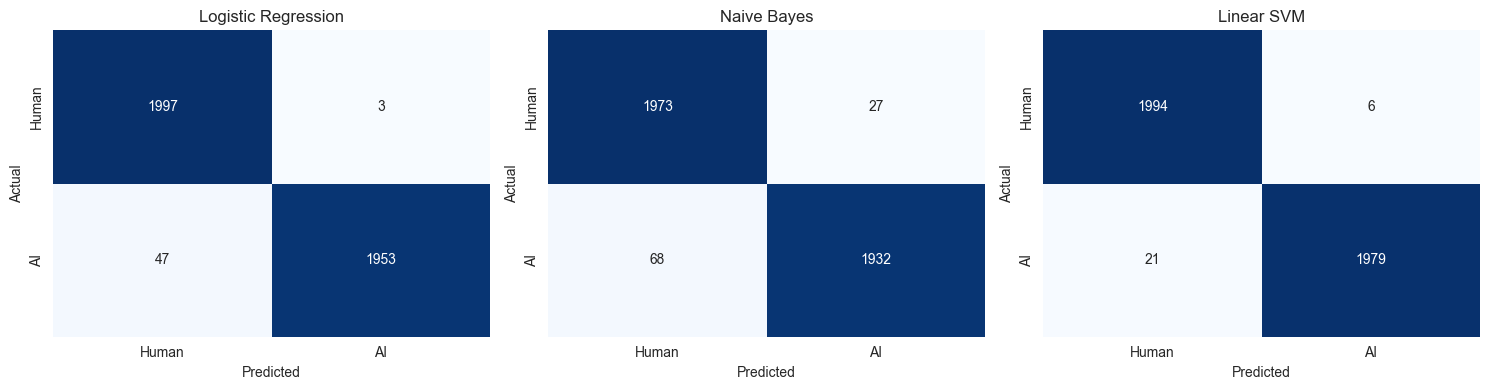

In [10]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Human', 'AI'], yticklabels=['Human', 'AI'])
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.savefig('confusion_matrices.png', dpi=150); plt.show()

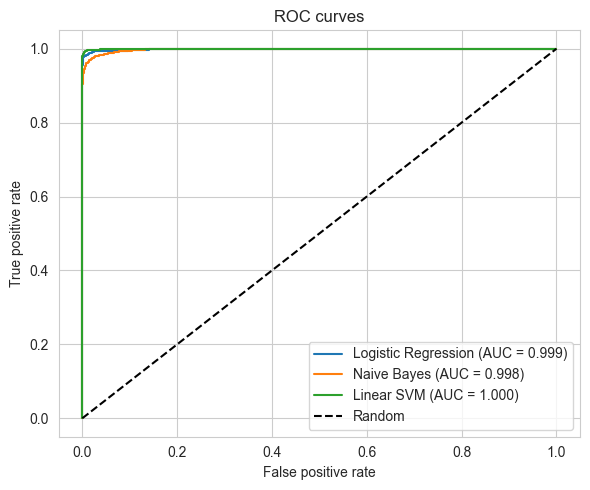

In [11]:
# ROC curves
plt.figure(figsize=(6, 5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, probs[name]):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.title('ROC curves')
plt.legend(); plt.tight_layout(); plt.savefig('roc_curves.png', dpi=150); plt.show()

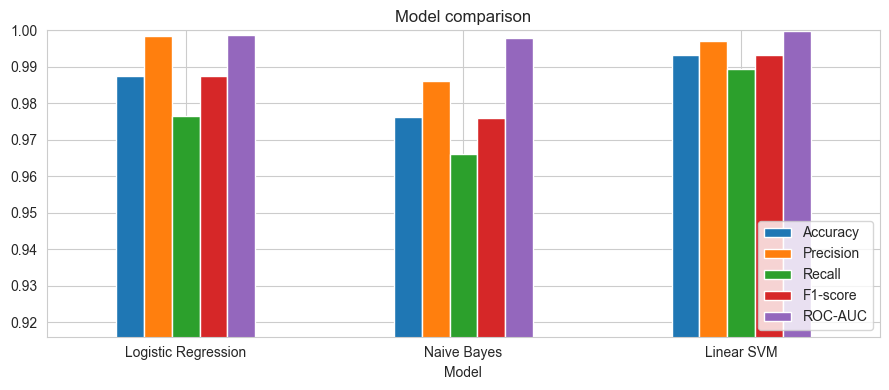

In [12]:
# Bar chart comparing models
results.plot(kind='bar', figsize=(9, 4)); plt.ylim(results.values.min() - 0.05, 1.0)
plt.title('Model comparison'); plt.xticks(rotation=0); plt.legend(loc='lower right')
plt.tight_layout(); plt.savefig('model_comparison.png', dpi=150); plt.show()

In [13]:
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy='most_frequent').fit(Xtr, y_train)
yd = dummy.predict(Xte)
baseline = {'Accuracy': accuracy_score(y_test, yd), 'Precision': precision_score(y_test, yd, zero_division=0),
            'Recall': recall_score(y_test, yd, zero_division=0), 'F1-score': f1_score(y_test, yd, zero_division=0), 'ROC-AUC': 0.5}
results_full = pd.concat([pd.DataFrame(baseline, index=['Majority-class baseline']), results]).round(4)
results_full

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Majority-class baseline,0.5000,0.0000,0.0000,0.0000,0.5000
Logistic Regression,0.9875,0.9985,0.9765,0.9874,0.9988
Naive Bayes,0.9762,0.9862,0.9660,0.9760,0.9978
Linear SVM,0.9932,0.9970,0.9895,0.9932,0.9997


In [14]:
import time
from sklearn.base import clone
eff = []
sample = X_test.iloc[:1000]
for name, m in models.items():
    mc = clone(m)
    t0 = time.time(); mc.fit(Xtr, y_train); train_s = time.time() - t0
    t0 = time.time(); mc.predict_proba(tfidf.transform(sample)); el = time.time() - t0
    eff.append({'Model': name, 'Train time (s)': round(train_s, 2), 'Inference (ms per 1000 essays)': round(el / len(sample) * 1e6, 1)})
efficiency = pd.DataFrame(eff).set_index('Model')
efficiency

,Train time (s),Inference (ms per 1000 essays)
Model,,
Logistic Regression,0.50,463.0
Naive Bayes,0.02,519.2
Linear SVM,0.61,472.5


In [15]:
from sklearn.feature_extraction.text import CountVectorizer
def run_cfg(vec):
    A = vec.fit_transform(X_train); Bm = vec.transform(X_test)
    clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(A, y_train)
    p = clf.predict_proba(Bm)[:, 1]; yh = (p >= 0.5).astype(int)
    return {'Accuracy': accuracy_score(y_test, yh), 'F1-score': f1_score(y_test, yh), 'ROC-AUC': roc_auc_score(y_test, p)}

configs = {
 'Full model (1-2 grams, no stop words, sublinear TF, 50k features)': TfidfVectorizer(stop_words='english', ngram_range=(1,2), max_features=50000, sublinear_tf=True),
 'Unigrams only':               TfidfVectorizer(stop_words='english', ngram_range=(1,1), max_features=50000, sublinear_tf=True),
 'Keep stop words':             TfidfVectorizer(stop_words=None,      ngram_range=(1,2), max_features=50000, sublinear_tf=True),
 'No sublinear TF scaling':     TfidfVectorizer(stop_words='english', ngram_range=(1,2), max_features=50000, sublinear_tf=False),
 'Only 10,000 features':        TfidfVectorizer(stop_words='english', ngram_range=(1,2), max_features=10000, sublinear_tf=True),
 'Raw word counts (no TF-IDF)': CountVectorizer(stop_words='english', ngram_range=(1,2), max_features=50000),
}
ablation = pd.DataFrame({k: run_cfg(v) for k, v in configs.items()}).T.round(4)
ablation

,Accuracy,F1-score,ROC-AUC
"Full model (1-2 grams, no stop words, sublinear TF, 50k features)",0.9875,0.9874,0.9988
Unigrams only,0.9858,0.9856,0.9983
Keep stop words,0.9898,0.9897,0.9993
No sublinear TF scaling,0.9870,0.9869,0.9980
"Only 10,000 features",0.9872,0.9871,0.9987
Raw word counts (no TF-IDF),0.9900,0.9899,0.9990


In [16]:
lr = models['Logistic Regression']
feat = np.array(tfidf.get_feature_names_out())
coef = lr.coef_[0]
top_ai    = feat[np.argsort(coef)[-15:][::-1]]
top_human = feat[np.argsort(coef)[:15]]
print('Top words/bigrams indicating AI    :', list(top_ai))
print('Top words/bigrams indicating Human :', list(top_human))

Top words/bigrams indicating AI    : ['important', 'conclusion', 'potential', 'additionally', 'super', 'essay', 'provide', 'hey', 'benefits', 'support', 'lead', 'impact', 'cool', 'gonna', 'goals']
Top words/bigrams indicating Human : ['people', 'car', 'student', 'going', 'reason', 'cars', 'kids', 'venus', 'home', 'school', 'dont', 'paragraph', 'percent', 'students', 'want']


In [17]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
pipe = make_pipeline(TfidfVectorizer(stop_words='english', ngram_range=(1,2), max_features=50000, sublinear_tf=True),
                     LogisticRegression(max_iter=1000))
cv = cross_val_score(pipe, df['clean'], df['label'], cv=5, scoring='f1')
print('5-fold F1 (Logistic Regression):', cv.round(4), '| mean =', cv.mean().round(4))

wrong = X_test[(preds['Logistic Regression'] != y_test.values)]
print('\nMisclassified by Logistic Regression:', len(wrong), 'of', len(y_test))
for t in wrong.head(3): print('-', t[:200], '...')

5-fold F1 (Logistic Regression): [0.9874 0.9876 0.9887 0.9884 0.9881] | mean = 0.988

Misclassified by Logistic Regression: 50 of 4000
- in this world everyone has twenty four hours for one day what are you doing with your day do you accomplish anything every day you have something you want to do but sometimes you find yourself inactiv ...
- in german suburb life goes on without cars by elisabeth rosenthal source we learn about vauban a suburban community in germany that has abandoned car usage according to the passage vauban s residents  ...
- the principal is considering making a change in school policy and she wants to know what the students think about it the principal is aware that many students have a grade c average and at least a gra ...


In [18]:
best = 'Logistic Regression'   # change to the best model in your results table
def predict_text(t):
    p = models[best].predict_proba(tfidf.transform([clean_text(t)]))[0, 1]
    return f"P(AI-generated) = {p:.3f} -> {'AI' if p >= 0.5 else 'Human'}"

print(predict_text("Write any paragraph here to test the model."))

P(AI-generated) = 0.476 -> Human


In [19]:
results_full.to_csv('results.csv'); efficiency.to_csv('efficiency.csv'); ablation.to_csv('ablation.csv')
print('Saved results.csv, efficiency.csv, ablation.csv and chart images.')

Saved results.csv, efficiency.csv, ablation.csv and chart images.
